findfont: Failed to find font weight bold for SimHei, now using 400.


   时间  反应器编号   温度   压力
0   1  R-101  300  1.0
1   2  R-101  305  1.1
2   3  R-101  310  1.2
3   4  R-103  315  1.3
4   5  R-103  320  1.4
<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   时间      14 non-null     int64  
 1   反应器编号   14 non-null     str    
 2   温度      14 non-null     int64  
 3   压力      14 non-null     float64
dtypes: float64(1), int64(2), str(1)
memory usage: 580.0 bytes
None
           时间     温度   压力
0  2023-01-01  300.0  1.1
1  2023-01-02  300.0  1.2
2  2023-01-03  300.0  1.3
3  2023-01-04  223.0  1.4
4  2023-01-05  210.0  1.5


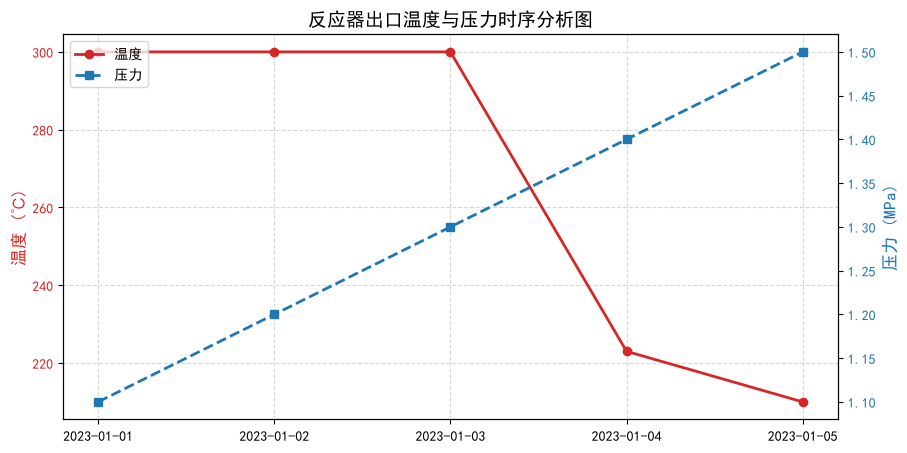

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 中文比字母数字大
plt.rcParams['font.sans-serif'] = ['SimHei']  # 设置中文字体
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题





data =({
    "时间": ["2023-01-01", "2023-01-02", "2023-01-03", "2023-01-04", "2023-01-05"],
    "温度": [300, np.nan, -999, 223, 210],               
    "压力": [1.1, 1.2, 1.3, 1.4, 1.5]
})  

df1 = pd.DataFrame(data)


df = pd.read_csv('化工测试数据.csv')
print(df.head())
print(df.info())

# 将-999替换为np.nan
df1 = df1.replace(-999, np.nan)

# 向前添加填补缺失值
df1 = df1.ffill()
print(df1)
# 1. 创建画布和左轴
fig, ax1 = plt.subplots(figsize=(10, 5))

# 2. 左轴画温度（红色实线圆点）
ax1.plot(df1['时间'], df1['温度'], color='tab:red', marker='o', linewidth=2, label='温度')
ax1.set_ylabel('温度 (℃)', color='tab:red', fontsize=12)
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.grid(True, linestyle='--', alpha=0.5)

# 3. 创建右轴（注意用 ax1.twinx()）
ax2 = ax1.twinx()

# 4. 右轴画压力（蓝色虚线方块）
ax2.plot(df1['时间'], df1['压力'], color='tab:blue', marker='s', linestyle='--', linewidth=2, label='压力')
ax2.set_ylabel('压力 (MPa)', color='tab:blue', fontsize=12)
ax2.tick_params(axis='y', labelcolor='tab:blue')

# 5. 合并图例放在左上角
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('反应器出口温度与压力时序分析图', fontsize=14, fontweight='bold')

# 【漏洞修复】保存图片（写在 show 之前）
plt.savefig('第一课考核图.png', dpi=300, bbox_inches='tight')
plt.show()













